# Notebook 03 — Business insights
**Dependency:** Complete Notebook 02 first; it saves `outputs/clustered_customers.csv` and `outputs/cluster_profiles.csv`.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

current = Path.cwd()
ROOT = current if (current / "data").exists() else current.parent
OUT_DIR = ROOT / "outputs"
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

clustered_file = OUT_DIR / "clustered_customers.csv"
if not clustered_file.exists():
    raise FileNotFoundError("Run Notebook 02 and its export cell before Notebook 03.")
df = pd.read_csv(clustered_file)
print("Number of customers:", len(df))
print("Cluster counts:")
print(df["Cluster"].value_counts().sort_index())

Number of customers: 2240
Cluster counts:
Cluster
0    1523
1     717
Name: count, dtype: int64


## Profile the customer segments
Compare average amounts and purchase counts. Higher `Recency` means a longer time **since** a purchase, therefore the customer has not bought as recently (according to this historical dataset).

,Customer_Count,Total_Spending,Purchase_Frequency,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds
Cluster,,,,,,,,,,
0,1523,834.32,15.60,49.31,434.66,33.06,231.68,47.38,33.94,53.60
1,717,120.39,6.04,48.69,26.26,11.96,29.45,16.59,12.46,23.67


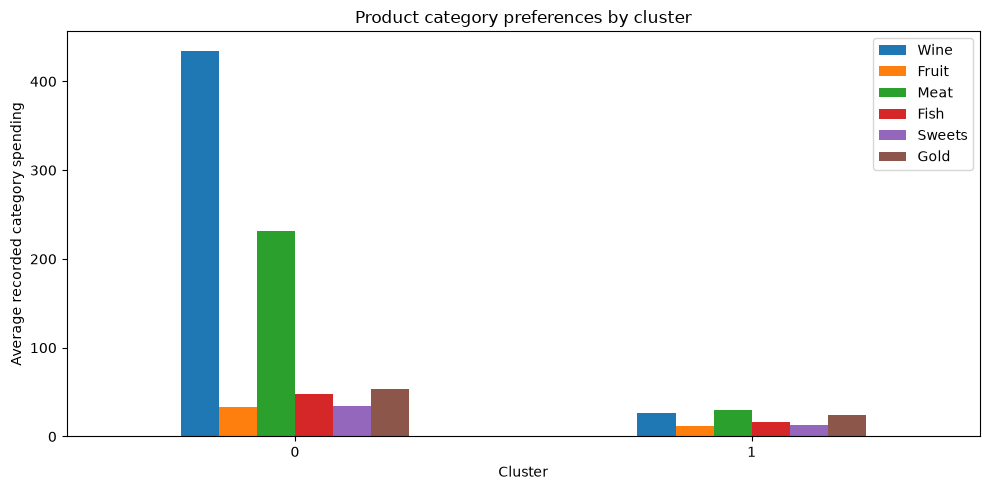

In [2]:
product_cols = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
profile_cols = ["Total_Spending", "Purchase_Frequency", "Recency"] + product_cols
profile = df.groupby("Cluster")[profile_cols].mean().round(2)
profile.insert(0, "Customer_Count", df.groupby("Cluster").size())
display(profile)

category_labels = {"MntWines": "Wine", "MntFruits": "Fruit", "MntMeatProducts": "Meat", "MntFishProducts": "Fish", "MntSweetProducts": "Sweets", "MntGoldProds": "Gold"}
preferred = df.groupby("Cluster")[product_cols].mean().rename(columns=category_labels)
preferred.plot(kind="bar", figsize=(10, 5))
plt.ylabel("Average recorded category spending")
plt.title("Product category preferences by cluster")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIG_DIR / "product_preferences_by_cluster.png", dpi=180)
plt.show()

## Describe the clusters in words
Use the actual table above to describe the clusters in the project README. Example phrasing (not assumed results): 'Cluster 1 makes more recorded purchases than the dataset average and has high category X spending; a targeted loyalty offer may suit it.' Explain that business actions are suggestions, not demonstrated causal outcomes.

In [3]:
overall_spend = df["Total_Spending"].mean()
overall_freq = df["Purchase_Frequency"].mean()
overall_recency = df["Recency"].mean()
print("OVERALL AVERAGES: spending=", round(overall_spend, 2), "purchases=", round(overall_freq, 2), "recency=", round(overall_recency, 2))
for cluster_id, row in profile.iterrows():
    print(f"\nCluster {cluster_id} (n={int(row['Customer_Count'])}):")
    print("Spending vs overall:", "above" if row['Total_Spending'] > overall_spend else "at/below")
    print("Purchases vs overall:", "above" if row['Purchase_Frequency'] > overall_freq else "at/below")
    print("Recency vs overall:", "higher (less recent)" if row['Recency'] > overall_recency else "lower (more recent)")
    top_category = max(product_cols, key=lambda c: row[c])
    print("Largest category amount:", category_labels[top_category])

OVERALL AVERAGES: spending= 605.8 purchases= 12.54 recency= 49.11

Cluster 0 (n=1523):
Spending vs overall: above
Purchases vs overall: above
Recency vs overall: higher (less recent)
Largest category amount: Wine

Cluster 1 (n=717):
Spending vs overall: at/below
Purchases vs overall: at/below
Recency vs overall: lower (more recent)
Largest category amount: Meat


## Save a short results checklist
Summarize the *actual* cluster descriptions in `README.md`, include figures from `outputs/figures`, and cite the Kaggle dataset.

In [4]:
# Verify that our graph is saved

graph_path = OUT_DIR / "figures" / "product_preferences_by_cluster.png"

print("File location:", graph_path.resolve())
print("File exists:", graph_path.exists())

if graph_path.exists():
    print("File size:", graph_path.stat().st_size, "bytes")
    print("Graph saved successfully!")
else:
    print("Graph not found!")

File location: /home/darknight/Projects/learning/Customer-Segmentation-Project/outputs/figures/product_preferences_by_cluster.png
File exists: True
File size: 52880 bytes
Graph saved successfully!
